In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("Program TA-02 Pemodelan dan Simulasi")
print("Library berhasil diimpor.")

Program TA-02 Pemodelan dan Simulasi
Library berhasil diimpor.


In [2]:

# TA-02 Pemodelan dan Simulasi
# Langkah 3: Implementasi Linear Congruential Generator (LCG)

def my_lcg(n, seed, a, c, m):
    """
    Menghasilkan n bilangan acak semu menggunakan algoritma LCG.

    Parameter:
    n    : jumlah bilangan yang dihasilkan
    seed : nilai awal (menggunakan NIM)
    a    : konstanta pengali
    c    : konstanta penambah
    m    : modulus
    """
    hasil = []
    x = seed

    for i in range(n):
        x = (a * x + c) % m
        u = x / m
        hasil.append(u)

    return hasil


# Parameter LCG sesuai modul
N = 1000
SEED = 301240016
a = 1664525
c = 1013904223
m = 2**32

# Membuat 1000 bilangan Uniform
data_uniform = my_lcg(N, SEED, a, c, m)

# Menampilkan beberapa hasil pertama
print("Jumlah data:", len(data_uniform))
print("Seed (NIM):", SEED)
print("Lima bilangan pertama:", data_uniform[:5])
print("Nilai minimum:", min(data_uniform))
print("Nilai maksimum:", max(data_uniform))

Jumlah data: 1000
Seed (NIM): 301240016
Lima bilangan pertama: [0.5354168375488371, 0.9475889508612454, 0.7345002873335034, 0.3268417725339532, 0.5374950512778014]
Nilai minimum: 0.00023212982341647148
Nilai maksimum: 0.9983033561147749


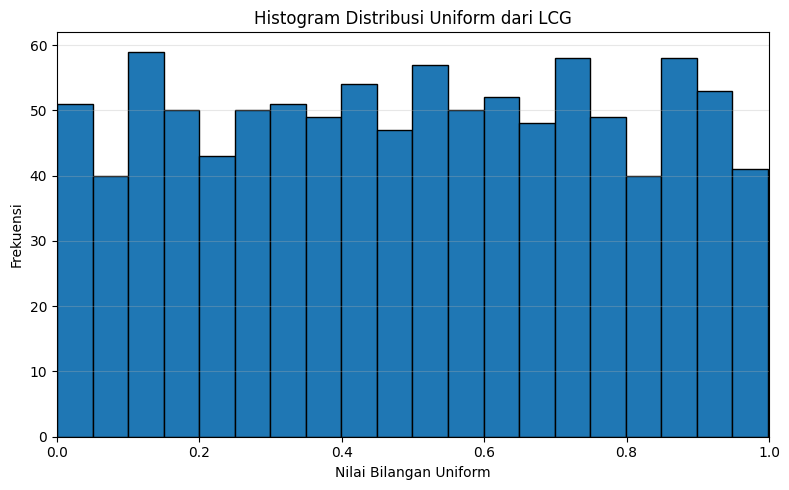

In [3]:

# Langkah 4: Visualisasi Distribusi Uniform

plt.figure(figsize=(8, 5))

plt.hist(
    data_uniform,
    bins=20,
    edgecolor="black"
)

plt.title("Histogram Distribusi Uniform dari LCG")
plt.xlabel("Nilai Bilangan Uniform")
plt.ylabel("Frekuensi")
plt.xlim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("histogram_uniform.png", dpi=300)
plt.show()

In [4]:

# Langkah 5: Inverse Transform untuk Distribusi Exponential

# Parameter distribusi Exponential sesuai modul
lam = 2

# Mengubah bilangan Uniform menjadi Exponential
data_exponential = [
    -np.log(1 - u) / lam
    for u in data_uniform
]

# Menghitung rata-rata hasil simulasi
mean_simulasi = np.mean(data_exponential)

# Rata-rata teoritis distribusi Exponential
mean_teoritis = 1 / lam

print("Jumlah data:", len(data_exponential))
print("Lambda:", lam)
print("Rata-rata simulasi:", mean_simulasi)
print("Rata-rata teoritis:", mean_teoritis)
print("Nilai minimum:", min(data_exponential))
print("Nilai maksimum:", max(data_exponential))

Jumlah data: 1000
Lambda: 2
Rata-rata simulasi: 0.48569629367015343
Rata-rata teoritis: 0.5
Nilai minimum: 0.00011607838485701901
Nilai maksimum: 3.1895515821768807


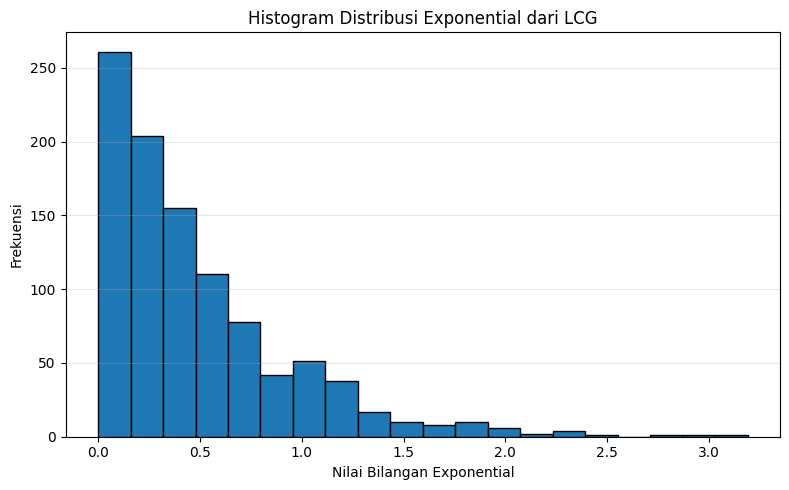

In [5]:

# Langkah 6: Visualisasi Distribusi Exponential

plt.figure(figsize=(8, 5))

plt.hist(
    data_exponential,
    bins=20,
    edgecolor="black"
)

plt.title("Histogram Distribusi Exponential dari LCG")
plt.xlabel("Nilai Bilangan Exponential")
plt.ylabel("Frekuensi")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("histogram_exponential.png", dpi=300)
plt.show()

In [6]:

# Langkah 7: Evaluasi Hasil Simulasi

selisih_mean = abs(mean_simulasi - mean_teoritis)

print("=== EVALUASI SIMULASI ===")
print(f"Rata-rata simulasi      : {mean_simulasi:.6f}")
print(f"Rata-rata teoritis      : {mean_teoritis:.6f}")
print(f"Selisih rata-rata       : {selisih_mean:.6f}")

if selisih_mean < 0.05:
    print("Hasil rata-rata simulasi cukup dekat dengan nilai teoritis.")
else:
    print("Hasil rata-rata simulasi memiliki selisih yang perlu diperhatikan.")

=== EVALUASI SIMULASI ===
Rata-rata simulasi      : 0.485696
Rata-rata teoritis      : 0.500000
Selisih rata-rata       : 0.014304
Hasil rata-rata simulasi cukup dekat dengan nilai teoritis.


In [7]:
from google.colab import files

files.download("histogram_uniform.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
from google.colab import files

files.download("histogram_exponential.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Analisis dan Kesimpulan TA-02

Pada praktikum ini, saya membuat pembangkit bilangan acak semu menggunakan metode Linear Congruential Generator (LCG). Nilai seed yang digunakan adalah NIM 301240016, dengan parameter a = 1664525, c = 1013904223, dan m = 2³². Dari proses tersebut, berhasil dihasilkan 1.000 bilangan Uniform yang nilainya berada pada rentang 0 sampai kurang dari 1.

Selanjutnya, bilangan Uniform diubah menjadi bilangan yang mengikuti distribusi Exponential menggunakan metode Inverse Transform dengan parameter lambda = 2. Rumus yang digunakan adalah T = -ln(1 - U) / lambda.

Hasil simulasi menunjukkan bahwa rata-rata data Exponential adalah 0,485696, sedangkan rata-rata teoritisnya adalah 0,5. Selisih kedua nilai tersebut sebesar 0,014304. Hasil ini menunjukkan bahwa rata-rata simulasi cukup dekat dengan nilai teoritis.

Berdasarkan praktikum ini, saya memahami bahwa LCG dapat digunakan untuk membangkitkan bilangan acak semu tanpa menggunakan fungsi random bawaan. Metode Inverse Transform juga dapat digunakan untuk mengubah bilangan Uniform menjadi distribusi Exponential. Namun, kedekatan rata-rata saja belum cukup untuk memastikan kualitas generator secara keseluruhan, sehingga pola histogram dan karakteristik bilangan yang dihasilkan tetap perlu diperiksa.